# **TP_N4 Architecture Transformer**

## Première partie (étapes 1 à 6)

1. Série temporelle `s = sin(x)` et fenêtres glissantes de longueur 10
2. RNN
3. LSTM
4. Transformer encodeur (2 têtes, `d_model = 16`)
5. GPT : continuation de texte
6. BERT : prédiction d'un mot masqué

Les étapes 1 à 4 tournent en quelques secondes sur CPU. Les étapes 5 et 6 téléchargent `gpt2` (environ 550 Mo) et `bert-base-multilingual-cased` (environ 700 Mo) au premier lancement.

Dépendances : `pip install torch transformers matplotlib`

In [1]:
import math
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device :", device)

PyTorch 2.15.0+cpu | device : cpu


## 1. Jeu de données : y = sin(x)

200 points entre 0 et 20. Chaque exemple est une fenêtre de 10 valeurs consécutives et la cible est la valeur qui suit : `[s0..s9] -> s10`, `[s1..s10] -> s11`, etc.

Le découpage train/test reste chronologique : on mélange les fenêtres seulement dans le train, sinon le test contiendrait des points voisins de ceux vus à l'entraînement.

X : (190, 10, 1) | Y : (190, 1)
train : (150, 10, 1) | test : (40, 10, 1)


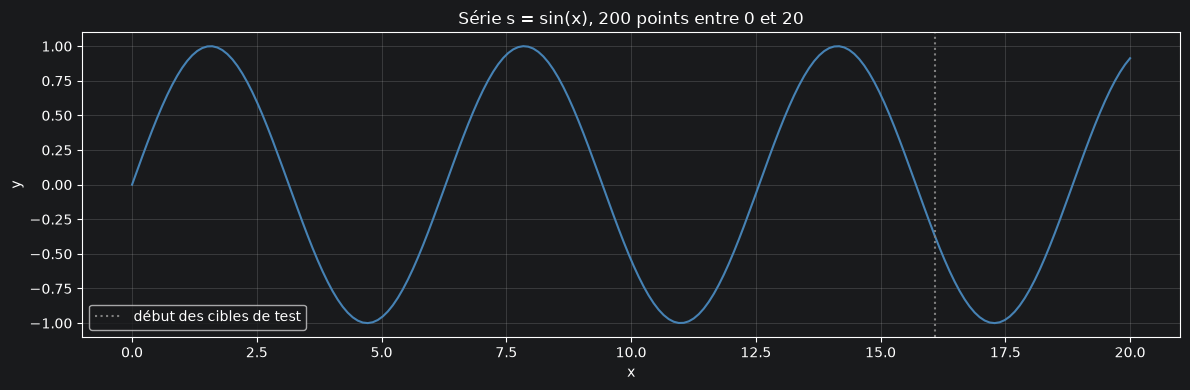

In [2]:
NB_POINTS = 200
LONGUEUR_SEQ = 10
NB_TRAIN = 150          # 150 fenêtres pour apprendre, 40 pour tester
BATCH_SIZE = 16

x_axe = torch.linspace(0, 20, NB_POINTS)
serie = torch.sin(x_axe)                       # (200,)


def fenetres_glissantes(serie, longueur):
    n = len(serie) - longueur
    X = torch.stack([serie[i:i + longueur] for i in range(n)])   # (190, 10)
    y = torch.stack([serie[i + longueur] for i in range(n)])     # (190,)
    return X.unsqueeze(-1), y.unsqueeze(-1)    # (190, 10, 1) et (190, 1)


X, Y = fenetres_glissantes(serie, LONGUEUR_SEQ)
print("X :", tuple(X.shape), "| Y :", tuple(Y.shape))

# Vérification de l'alignement : X[2] = s2..s11 et Y[2] = s12
assert torch.equal(X[2, :, 0], serie[2:12]) and Y[2].item() == serie[12].item()

X_train, Y_train = X[:NB_TRAIN], Y[:NB_TRAIN]
X_test, Y_test = X[NB_TRAIN:], Y[NB_TRAIN:]
print("train :", tuple(X_train.shape), "| test :", tuple(X_test.shape))

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(X_train, Y_train),
                          batch_size=BATCH_SIZE, shuffle=True, generator=g)
test_loader = DataLoader(TensorDataset(X_test, Y_test),
                         batch_size=BATCH_SIZE, shuffle=False)

# La première cible du test est s160, donc x_axe[160] marque la frontière.
plt.figure(figsize=(12, 4))
plt.plot(x_axe, serie, color="steelblue")
plt.axvline(x_axe[NB_TRAIN + LONGUEUR_SEQ], color="gray", linestyle=":", label="début des cibles de test")
plt.title("Série s = sin(x), 200 points entre 0 et 20")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Outils communs

Une seule boucle d'entraînement et une seule fonction d'évaluation servent aux trois modèles, pour que la comparaison se fasse dans les mêmes conditions (même optimiseur, même perte, mêmes lots).

La cible est une valeur réelle, donc on mesure l'erreur (MSE, RMSE, MAE) : une exactitude n'a pas de sens ici.

In [4]:
EPOCHS = 100
LR = 0.01
resultats = {}          # nom du modèle -> métriques et prédictions de test


def compter_parametres(modele):
    return sum(p.numel() for p in modele.parameters())


def entrainer(modele, loader, epochs=EPOCHS, lr=LR):
    modele.to(device)
    critere = nn.MSELoss()
    optimiseur = torch.optim.Adam(modele.parameters(), lr=lr)
    # Le pas diminue en cours de route, ce qui évite les pics de fin d'entraînement.
    planning = torch.optim.lr_scheduler.CosineAnnealingLR(optimiseur, T_max=epochs)
    historique = []

    for epoch in range(epochs):
        modele.train()
        somme, n = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            perte = critere(modele(xb), yb)

            optimiseur.zero_grad()
            perte.backward()
            optimiseur.step()

            somme += perte.item() * len(xb)
            n += len(xb)

        planning.step()
        historique.append(somme / n)
        if (epoch + 1) % 20 == 0:
            print(f"Epoch {epoch + 1:3d} | MSE train : {historique[-1]:.6f}")
    return historique


@torch.no_grad()
def evaluer(modele, loader):
    modele.eval()
    preds, reels = [], []
    for xb, yb in loader:
        preds.append(modele(xb.to(device)).cpu())
        reels.append(yb)
    preds, reels = torch.cat(preds), torch.cat(reels)
    mse = nn.functional.mse_loss(preds, reels).item()
    mae = (preds - reels).abs().mean().item()
    return preds.squeeze(1), reels.squeeze(1), mse, math.sqrt(mse), mae


@torch.no_grad()
def afficher_echantillons(nom, modele):
    # Les trois premières fenêtres donnent s10, s11, s12 (zone d'entraînement).
    # Les trois premières du test donnent s160, s161, s162.
    idx = [0, 1, 2, NB_TRAIN, NB_TRAIN + 1, NB_TRAIN + 2]
    modele.eval()
    pred = modele(X[idx].to(device)).cpu().squeeze(1)
    print(f"\n{nom} : exemples")
    for i, p in zip(idx, pred):
        zone = "train" if i < NB_TRAIN else "test "
        print(f"  s{i + LONGUEUR_SEQ:<3d} ({zone}) réel = {Y[i].item():+.4f} | prédit = {p.item():+.4f}")


def tester(nom, modele, historique):
    preds, reels, mse, rmse, mae = evaluer(modele, test_loader)
    resultats[nom] = dict(preds=preds.numpy(), reels=reels.numpy(), mse=mse, rmse=rmse,
                          mae=mae, historique=historique, params=compter_parametres(modele))
    print(f"\n{nom} | test : MSE = {mse:.6f} | RMSE = {rmse:.4f} | MAE = {mae:.4f}")
    afficher_echantillons(nom, modele)


def tracer_predictions(nom, couleur="red"):
    r = resultats[nom]
    plt.figure(figsize=(12, 4.5))
    plt.plot(r["reels"], label="Valeurs réelles", color="blue", linewidth=2)
    plt.plot(r["preds"], label=f"Prédictions du {nom}", color=couleur, linestyle="--", linewidth=2)
    plt.title(f"{nom} : valeurs réelles et prédictions (test)")
    plt.xlabel("Indice de l'échantillon de test")
    plt.ylabel("Valeur")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 2. RNN

`nn.RNN` lit les 10 valeurs une par une. À chaque pas : `h_t = tanh(W_x x_t + W_h h_(t-1) + b)`, avec `h_0 = 0`. On garde seulement l'état caché du dernier pas pour la couche linéaire.

Formes : `(B, 10, 1) -> (B, 10, 16) -> (B, 16) -> (B, 1)`

In [5]:
class SimpleRNN(nn.Module):
    def __init__(self, hidden_size=16):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.sortie = nn.Linear(hidden_size, 1)

    def forward(self, x):                      # x : (B, 10, 1)
        etats, _ = self.rnn(x)                 # (B, 10, 16), h_0 = 0 par défaut
        dernier = etats[:, -1, :]              # (B, 16)
        return self.sortie(dernier)            # (B, 1)


torch.manual_seed(SEED)
rnn = SimpleRNN()
print(rnn)
print("paramètres :", compter_parametres(rnn))
print("sortie sur un lot :", tuple(rnn(X_train[:4]).shape))   # (4, 1)

SimpleRNN(
  (rnn): RNN(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)
paramètres : 321
sortie sur un lot : (4, 1)


Epoch  20 | MSE train : 0.000219
Epoch  40 | MSE train : 0.000059
Epoch  60 | MSE train : 0.000010
Epoch  80 | MSE train : 0.000006
Epoch 100 | MSE train : 0.000005

RNN | test : MSE = 0.000006 | RMSE = 0.0025 | MAE = 0.0021

RNN : exemples
  s10  (train) réel = +0.8442 | prédit = +0.8447
  s11  (train) réel = +0.8937 | prédit = +0.8941
  s12  (train) réel = +0.9342 | prédit = +0.9341
  s160 (test ) réel = -0.3639 | prédit = -0.3608
  s161 (test ) réel = -0.4555 | prédit = -0.4533
  s162 (test ) réel = -0.5425 | prédit = -0.5418


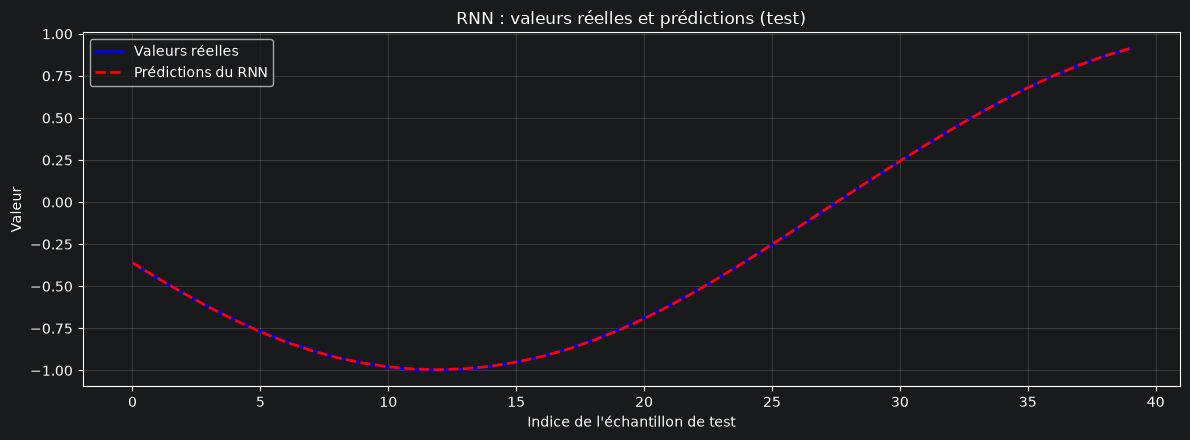

In [6]:
hist_rnn = entrainer(rnn, train_loader)
tester("RNN", rnn, hist_rnn)
tracer_predictions("RNN", "red")

## 3. LSTM

Même montage que le RNN, mais la cellule garde en plus un état `c_t` contrôlé par trois portes (oubli, entrée, sortie). `nn.LSTM` renvoie `(etats, (h_n, c_n))`, et on utilise là aussi la dernière position.

In [7]:
class SimpleLSTM(nn.Module):
    def __init__(self, hidden_size=16):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, num_layers=1, batch_first=True)
        self.sortie = nn.Linear(hidden_size, 1)

    def forward(self, x):                      # x : (B, 10, 1)
        etats, (h_n, c_n) = self.lstm(x)       # etats : (B, 10, 16)
        dernier = etats[:, -1, :]              # (B, 16)
        return self.sortie(dernier)            # (B, 1)


torch.manual_seed(SEED)
lstm = SimpleLSTM()
print(lstm)
print("paramètres :", compter_parametres(lstm))
print("sortie sur un lot :", tuple(lstm(X_train[:4]).shape))

SimpleLSTM(
  (lstm): LSTM(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)
paramètres : 1233
sortie sur un lot : (4, 1)


Epoch  20 | MSE train : 0.000040
Epoch  40 | MSE train : 0.000026
Epoch  60 | MSE train : 0.000007
Epoch  80 | MSE train : 0.000004
Epoch 100 | MSE train : 0.000003

LSTM | test : MSE = 0.000003 | RMSE = 0.0017 | MAE = 0.0014

LSTM : exemples
  s10  (train) réel = +0.8442 | prédit = +0.8458
  s11  (train) réel = +0.8937 | prédit = +0.8953
  s12  (train) réel = +0.9342 | prédit = +0.9351
  s160 (test ) réel = -0.3639 | prédit = -0.3630
  s161 (test ) réel = -0.4555 | prédit = -0.4559
  s162 (test ) réel = -0.5425 | prédit = -0.5441


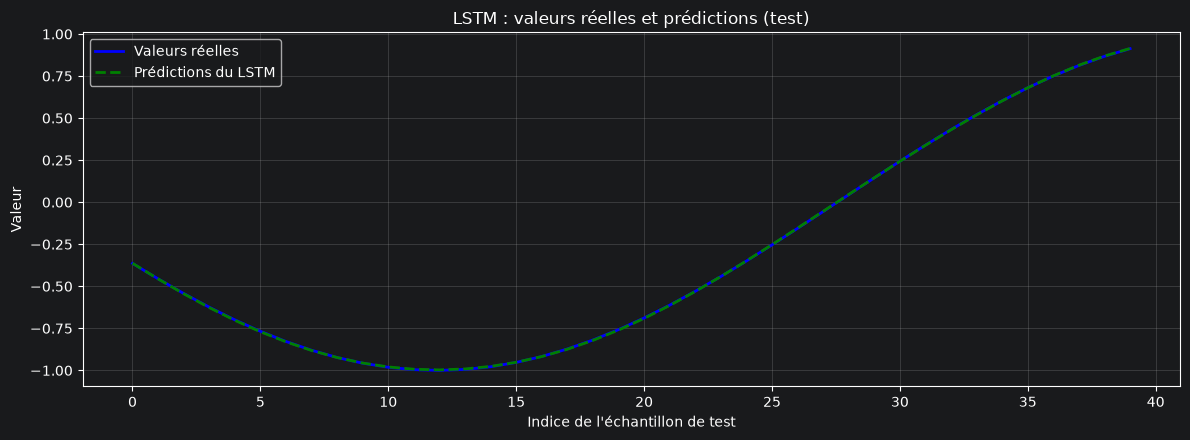

In [8]:
hist_lstm = entrainer(lstm, train_loader)
tester("LSTM", lstm, hist_lstm)
tracer_predictions("LSTM", "green")

## 4. Transformer (encodeur)

On suit le schéma du tableau :

```
x (B,10,1) -> Linear 1->16 -> + embedding de position (indices 0..9)
           -> Multi-Head Self-Attention (2 têtes, d_model = 16)
           -> Add & LayerNorm
           -> Feed Forward 16 -> 32 -> 16 (ReLU)
           -> Add & LayerNorm
           -> dernière position [:, -1, :] -> Linear 16->1
```

Le bloc est écrit à la main avec `nn.MultiheadAttention`, `nn.LayerNorm` et deux `nn.Linear`, pour que chaque flèche du schéma corresponde à une ligne de code. Il n'y a pas de masque causal : chaque position peut regarder toutes les autres, y compris les positions suivantes de la fenêtre. Ce n'est pas un problème ici, la fenêtre est entièrement connue et la cible est hors de la fenêtre.

In [9]:
class BlocEncodeur(nn.Module):
    def __init__(self, d_model=16, nb_tetes=2, d_ff=32, dropout=0.0):
        super().__init__()
        self.attention = nn.MultiheadAttention(d_model, nb_tetes, dropout=dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model),
        )
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, retourner_poids=False):          # x : (B, T, d_model)
        att, poids = self.attention(x, x, x, need_weights=retourner_poids)
        x = self.norm1(x + self.dropout(att))              # Add & Norm (résiduelle 1)
        x = self.norm2(x + self.dropout(self.ff(x)))       # Add & Norm (résiduelle 2)
        return x, poids                                    # poids : (B, T, T) ou None


class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10, d_model=16, nb_tetes=2, d_ff=32):
        super().__init__()
        self.projection = nn.Linear(1, d_model)
        self.positions = nn.Embedding(longueur_max, d_model)
        self.bloc = BlocEncodeur(d_model, nb_tetes, d_ff)
        self.sortie = nn.Linear(d_model, 1)

    def forward(self, x, retourner_poids=False):          # x : (B, 10, 1)
        T = x.size(1)
        h = self.projection(x)                             # (B, 10, 16)
        indices = torch.arange(T, device=x.device)         # 0, 1, ..., 9
        h = h + self.positions(indices).unsqueeze(0)       # (B, 10, 16)
        h, poids = self.bloc(h, retourner_poids)           # (B, 10, 16)
        y = self.sortie(h[:, -1, :])                       # (B, 16) -> (B, 1)
        return (y, poids) if retourner_poids else y


torch.manual_seed(SEED)
transformer = MiniTransformer(longueur_max=LONGUEUR_SEQ)
print(transformer)
print("paramètres :", compter_parametres(transformer))

y_test_forme, poids_test = transformer(X_train[:4], retourner_poids=True)
print("sortie :", tuple(y_test_forme.shape), "| poids d'attention :", tuple(poids_test.shape))

MiniTransformer(
  (projection): Linear(in_features=1, out_features=16, bias=True)
  (positions): Embedding(10, 16)
  (bloc): BlocEncodeur(
    (attention): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
    )
    (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
    (ff): Sequential(
      (0): Linear(in_features=16, out_features=32, bias=True)
      (1): ReLU()
      (2): Linear(in_features=32, out_features=16, bias=True)
    )
    (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)
paramètres : 2433
sortie : (4, 1) | poids d'attention : (4, 10, 10)


Epoch  20 | MSE train : 0.000031
Epoch  40 | MSE train : 0.000014
Epoch  60 | MSE train : 0.000003
Epoch  80 | MSE train : 0.000002
Epoch 100 | MSE train : 0.000002

Transformer | test : MSE = 0.000002 | RMSE = 0.0015 | MAE = 0.0013

Transformer : exemples
  s10  (train) réel = +0.8442 | prédit = +0.8451
  s11  (train) réel = +0.8937 | prédit = +0.8946
  s12  (train) réel = +0.9342 | prédit = +0.9344
  s160 (test ) réel = -0.3639 | prédit = -0.3632
  s161 (test ) réel = -0.4555 | prédit = -0.4564
  s162 (test ) réel = -0.5425 | prédit = -0.5447


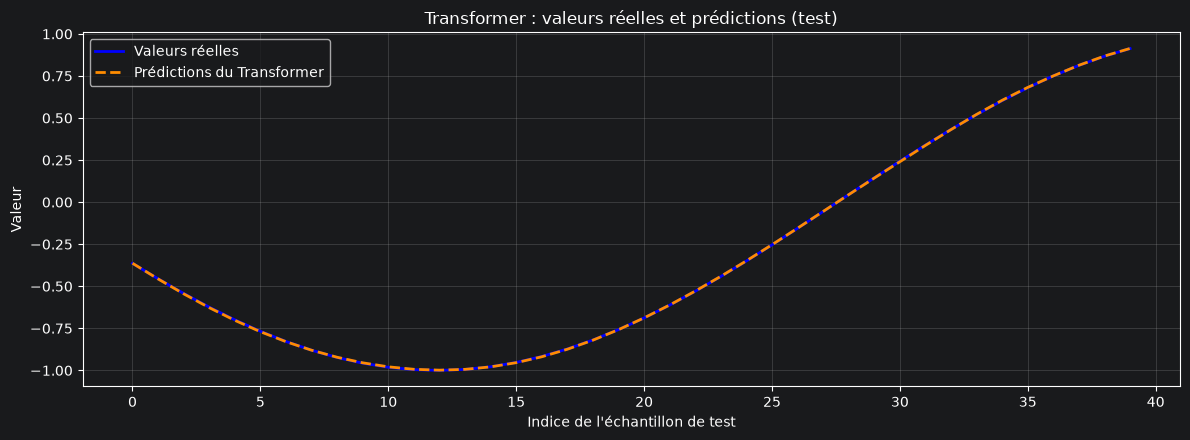

In [10]:
hist_transfo = entrainer(transformer, train_loader)
tester("Transformer", transformer, hist_transfo)
tracer_predictions("Transformer", "darkorange")

Poids d'attention (moyenne des 2 têtes) pour la première fenêtre de test : la ligne `i` indique où la position `i` va chercher son information.

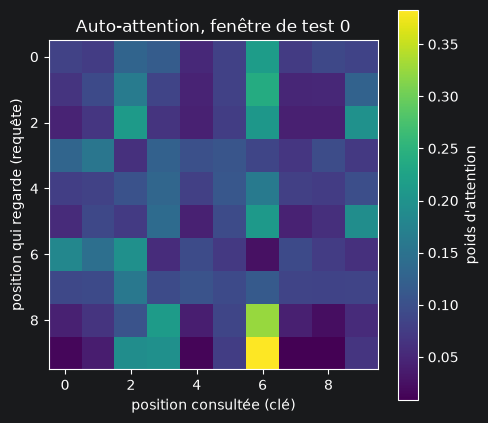

somme d'une ligne : 1.0000001192092896


In [11]:
transformer.eval()
with torch.no_grad():
    _, poids = transformer(X_test[:1].to(device), retourner_poids=True)   # (1, 10, 10)

plt.figure(figsize=(5, 4.5))
plt.imshow(poids[0].cpu().numpy(), cmap="viridis")
plt.colorbar(label="poids d'attention")
plt.title("Auto-attention, fenêtre de test 0")
plt.xlabel("position consultée (clé)")
plt.ylabel("position qui regarde (requête)")
plt.tight_layout()
plt.show()

print("somme d'une ligne :", poids[0, -1].sum().item())   # softmax : 1.0

## Comparaison RNN / LSTM / Transformer

Modèle       paramètres     MSE test  RMSE test   MAE test
RNN                 321     0.000006     0.0025     0.0021
LSTM               1233     0.000003     0.0017     0.0014
Transformer        2433     0.000002     0.0015     0.0013

MSE de test la plus basse : Transformer


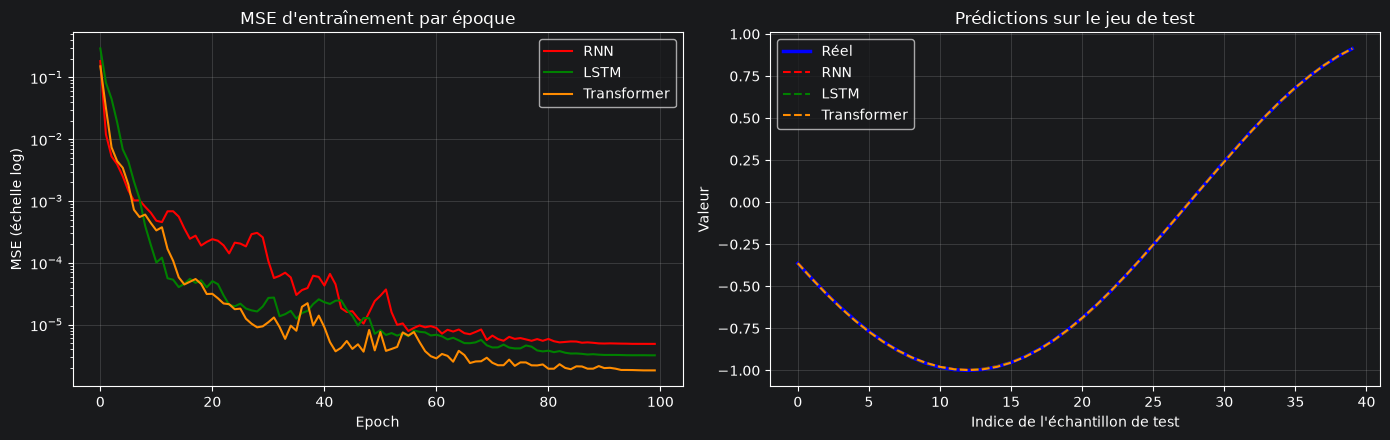

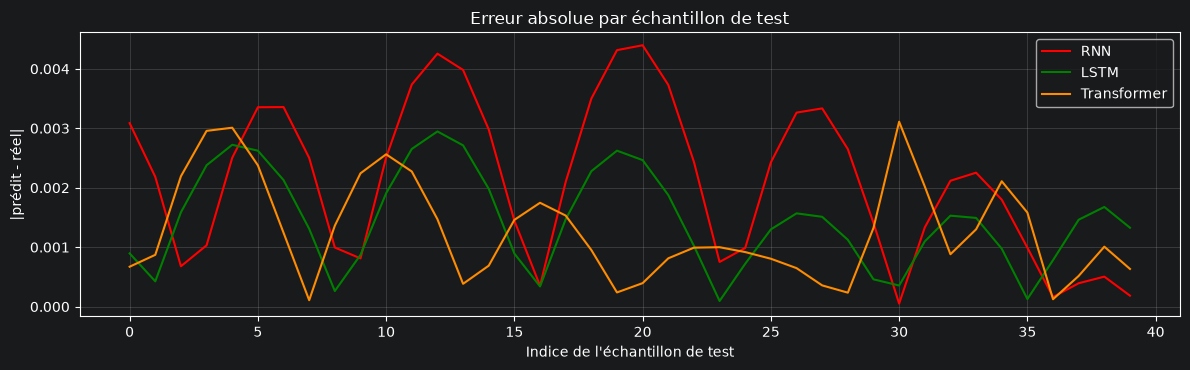

In [12]:
print(f"{'Modèle':<12} {'paramètres':>10} {'MSE test':>12} {'RMSE test':>10} {'MAE test':>10}")
for nom, r in resultats.items():
    print(f"{nom:<12} {r['params']:>10d} {r['mse']:>12.6f} {r['rmse']:>10.4f} {r['mae']:>10.4f}")

meilleur = min(resultats, key=lambda n: resultats[n]["mse"])
print("\nMSE de test la plus basse :", meilleur)

couleurs = {"RNN": "red", "LSTM": "green", "Transformer": "darkorange"}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for nom, r in resultats.items():
    axes[0].semilogy(r["historique"], label=nom, color=couleurs[nom])
axes[0].set_title("MSE d'entraînement par époque")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE (échelle log)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

reels = next(iter(resultats.values()))["reels"]
axes[1].plot(reels, color="blue", linewidth=2.5, label="Réel")
for nom, r in resultats.items():
    axes[1].plot(r["preds"], linestyle="--", color=couleurs[nom], label=nom)
axes[1].set_title("Prédictions sur le jeu de test")
axes[1].set_xlabel("Indice de l'échantillon de test")
axes[1].set_ylabel("Valeur")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Erreur absolue par échantillon de test
plt.figure(figsize=(12, 3.8))
for nom, r in resultats.items():
    plt.plot(np.abs(r["preds"] - r["reels"]), label=nom, color=couleurs[nom])
plt.title("Erreur absolue par échantillon de test")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("|prédit - réel|")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. GPT : continuer un texte

GPT est un décodeur seul. Son auto-attention est causale : la position `i` ne voit que les positions `0..i`. Le modèle prédit le token suivant, l'ajoute à l'entrée et recommence.

On utilise `gpt2` préentraîné (Hugging Face). Entraîner un GPT sur un petit corpus fait l'objet de l'exercice 2 de la deuxième partie.

In [19]:
from transformers import AutoTokenizer, AutoModelForCausalLM

nom_gpt = "gpt2"
tok_gpt = AutoTokenizer.from_pretrained(nom_gpt)
gpt = AutoModelForCausalLM.from_pretrained(nom_gpt).to(device)
gpt.eval()

# GPT-2 n'a pas de token de padding : on réutilise le token de fin de texte.
tok_gpt.pad_token = tok_gpt.eos_token
gpt.config.pad_token_id = tok_gpt.pad_token_id

print("paramètres :", compter_parametres(gpt))
print("masque causal pour 5 tokens (1 = visible) :")
print(torch.tril(torch.ones(5, 5, dtype=torch.int)))

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 303.87it/s]

paramètres : 124439808
masque causal pour 5 tokens (1 = visible) :
tensor([[1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1]], dtype=torch.int32)


In [20]:
@torch.no_grad()
def continuer_texte(amorce, max_new_tokens=40, temperature=0.8, top_p=0.9, graine=0):
    entrees = tok_gpt(amorce, return_tensors="pt").to(device)
    torch.manual_seed(graine)
    sortie = gpt.generate(
        **entrees,
        max_new_tokens=max_new_tokens,
        do_sample=True,
        temperature=temperature,
        top_p=top_p,
        pad_token_id=tok_gpt.pad_token_id,
    )
    return tok_gpt.decode(sortie[0], skip_special_tokens=True)


@torch.no_grad()
def tokens_suivants(amorce, k=5):
    ids = tok_gpt(amorce, return_tensors="pt")["input_ids"].to(device)
    logits = gpt(ids).logits[0, -1]                 # dernier token seulement
    probas = torch.softmax(logits, dim=-1)
    p, i = torch.topk(probas, k)
    return [(tok_gpt.decode([idx]), prob.item()) for prob, idx in zip(p, i)]


amorces = [
    "Artificial intelligence can help people",
    "Press and organization",
    "The capital of Morocco is",
]

for amorce in amorces:
    ids = tok_gpt(amorce, return_tensors="pt")["input_ids"]
    print(f"\nAmorce : {amorce!r} ({ids.shape[1]} tokens, entrée {tuple(ids.shape)})")
    print("  candidats pour le token suivant :")
    for mot, p in tokens_suivants(amorce):
        print(f"    {p:6.2%} | {mot!r}")
    print("  texte généré :")
    print("   ", continuer_texte(amorce).replace("\n", " "))


Amorce : 'Artificial intelligence can help people' (6 tokens, entrée (1, 6))
  candidats pour le token suivant :
     7.17% | ' to'
     5.87% | ' with'
     4.97% | ' better'
     4.73% | ' understand'
     3.62% | ' make'
  texte généré :
    Artificial intelligence can help people understand what their behavior is like and how they respond to it. This helps the machine understand what is happening around them and to be able to make more effective decisions.  However, when you look

Amorce : 'Press and organization' (3 tokens, entrée (1, 3))
  candidats pour le token suivant :
     8.70% | '.'
     7.36% | ' of'
     6.78% | ','
     4.40% | '\n'
     2.50% | ':'
  texte généré :
    Press and organization, and their organization, the International Association of Women in the Field of Obstetrics and Gynecology (IASOP), is a group of women who have experience in a variety of areas of obst

Amorce : 'The capital of Morocco is' (5 tokens, entrée (1, 5))
  candidats pour le token suivan

Vérification de la causalité : si on change le dernier token, les logits de toutes les positions précédentes doivent rester identiques. Seule la dernière position peut bouger.

In [21]:
amorce = "Artificial intelligence can help people"
ids = tok_gpt(amorce, return_tensors="pt")["input_ids"].to(device)

ids_modifie = ids.clone()
remplacant = tok_gpt.encode(" banana")[0]
if remplacant == ids[0, -1].item():
    remplacant = tok_gpt.encode(" house")[0]
ids_modifie[0, -1] = remplacant

with torch.no_grad():
    l1 = gpt(ids).logits
    l2 = gpt(ids_modifie).logits

avant_inchange = torch.allclose(l1[:, :-1], l2[:, :-1], atol=1e-4)
dernier_change = not torch.allclose(l1[:, -1], l2[:, -1], atol=1e-4)
print("positions précédentes inchangées :", avant_inchange)
print("dernière position modifiée       :", dernier_change)

positions précédentes inchangées : True
dernière position modifiée       : True


## 6. BERT : retrouver un mot masqué

BERT est un encodeur seul. Il n'a pas de masque causal : le token `[MASK]` voit tout ce qui est à sa gauche et à sa droite. On lit le vecteur de sortie à la position du masque, la tête de langage le projette sur le vocabulaire et le softmax donne les probabilités.

Modèle : `bert-base-multilingual-cased` (il connaît le français et respecte la casse). Un `[MASK]` correspond à un seul token du vocabulaire, donc un mot rare découpé en plusieurs morceaux ne peut pas ressortir en entier.

In [16]:
from transformers import AutoModelForMaskedLM

nom_bert = "bert-base-multilingual-cased"
tok_bert = AutoTokenizer.from_pretrained(nom_bert)
bert = AutoModelForMaskedLM.from_pretrained(nom_bert).to(device)
bert.eval()

print("paramètres :", compter_parametres(bert))
print("token de masque :", tok_bert.mask_token, "| id :", tok_bert.mask_token_id)

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 944.63it/s]
[transformers] BertForMaskedLM LOAD REPORT from: bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


paramètres : 177974523
token de masque : [MASK] | id : 103


In [17]:
@torch.no_grad()
def completer_masque(texte, attendu=None, k=5):
    entrees = tok_bert(texte, return_tensors="pt").to(device)
    ids = entrees["input_ids"][0]
    positions = (ids == tok_bert.mask_token_id).nonzero(as_tuple=True)[0]
    assert len(positions) == 1, "une seule position [MASK] par phrase"
    pos = positions.item()

    logits = bert(**entrees).logits[0, pos]          # (taille_vocabulaire,)
    probas = torch.softmax(logits, dim=-1)
    top_p, top_i = torch.topk(probas, k)

    print(f"\nTexte : {texte}  (entrée {tuple(entrees['input_ids'].shape)}, masque en position {pos})")
    candidats = []
    for p, i in zip(top_p, top_i):
        mot = tok_bert.convert_ids_to_tokens(i.item())
        candidats.append(mot)
        print(f"  {p.item():6.2%} | {mot:<12} | {texte.replace(tok_bert.mask_token, mot)}")

    if attendu is not None:
        if attendu in candidats:
            print(f"  mot attendu {attendu!r} : rang {candidats.index(attendu) + 1} sur {k}")
        else:
            print(f"  mot attendu {attendu!r} : absent du top {k}")
    return candidats


tests = [
    ("Rabat est la [MASK] du Maroc.", "capitale"),
    ("[MASK] est la capitale du Maroc.", "Rabat"),
    ("Casablanca est la plus grande [MASK] du Maroc.", "ville"),
    ("Le Maroc est situé en [MASK] du Nord.", "Afrique"),
    ("Marrakech est surnommée la ville [MASK].", "rouge"),
]

for texte, attendu in tests:
    completer_masque(texte, attendu)


Texte : Rabat est la [MASK] du Maroc.  (entrée (1, 9), masque en position 4)
  86.06% | capitale     | Rabat est la capitale du Maroc.
   5.19% | ville        | Rabat est la ville du Maroc.
   5.03% | préfecture   | Rabat est la préfecture du Maroc.
   0.85% | Rabat        | Rabat est la Rabat du Maroc.
   0.58% | capital      | Rabat est la capital du Maroc.
  mot attendu 'capitale' : rang 1 sur 5

Texte : [MASK] est la capitale du Maroc.  (entrée (1, 9), masque en position 1)
  67.50% | Casablanca   | Casablanca est la capitale du Maroc.
   7.24% | Rabat        | Rabat est la capitale du Maroc.
   7.19% | Elle         | Elle est la capitale du Maroc.
   2.15% | capitale     | capitale est la capitale du Maroc.
   1.59% | .            | . est la capitale du Maroc.
  mot attendu 'Rabat' : rang 2 sur 5

Texte : Casablanca est la plus grande [MASK] du Maroc.  (entrée (1, 11), masque en position 6)
  61.64% | ville        | Casablanca est la plus grande ville du Maroc.
  29.21% | Casabla

Vérification de la bidirectionnalité : on remplace un token situé à droite du masque. Contrairement à GPT, les logits au niveau du masque doivent changer.

In [18]:
texte = "Rabat est la [MASK] du Maroc."
entrees = tok_bert(texte, return_tensors="pt").to(device)
ids = entrees["input_ids"]
pos = (ids[0] == tok_bert.mask_token_id).nonzero(as_tuple=True)[0].item()

ids_modifie = ids.clone()
ids_modifie[0, pos + 1] = tok_bert.convert_tokens_to_ids("de")   # "du" devient "de"

with torch.no_grad():
    l1 = bert(input_ids=ids, attention_mask=entrees["attention_mask"]).logits[0, pos]
    l2 = bert(input_ids=ids_modifie, attention_mask=entrees["attention_mask"]).logits[0, pos]

print("tokens :", tok_bert.convert_ids_to_tokens(ids[0]))
print("le masque tient compte du contexte de droite :", not torch.allclose(l1, l2, atol=1e-4))

tokens : ['[CLS]', 'Rabat', 'est', 'la', '[MASK]', 'du', 'Maroc', '.', '[SEP]']
le masque tient compte du contexte de droite : True
